# Nested models: moments, log p, concentration and entropy
M1 Gaussian (Scat2) ⊂ M2 (L_6 + scalar on the Q=1 Morlet bank; its Db4 variant puts the scalar potentials on the decimated, orthonormal Db4 DWT) ⊂ M3 (+ Q=3 scalar) ⊂ M4 (parked). **To add a model, add one line to `models.py`.**

Run on Jean Zay. Needs `saved_results/` (samples) and the `.npz` of `python nested_models/analyse_nested.py` (via `launch_analysis.sh`).
Convention: p ∝ exp(+θ·φ), so −log p = log Z − θ·φ; log Z is the lower bound H_bound + θ·m_target, so the *width* of −log p is exact and its level carries the moment-matching residual (`gap`).

In [1]:
%matplotlib inline
import sys
from pathlib import Path
NM = Path.cwd() if (Path.cwd() / 'models.py').exists() else Path.cwd() / 'nested_models'
sys.path[:0] = [str(NM), str(NM.parent), str(NM.parent / 'turbulence')]
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import logp_entropy as le, plots, stats_extra as se, gaussian_check as gcheck, dwt_marginals as dm
from run_comparison import *
from codes.utils_entropy import data_gaussian_entropy
from models import MODELS, SEEDS
%matplotlib inline
pd.set_option('display.float_format', '{:.3f}'.format, 'display.width', 250, 'display.max_rows', 100)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})

In [2]:
SEED, THRESHOLD = 900, 1e-8                     # samples and statistics: seed 900; the .npz tables use every available seed
runs, missing = load_runs(MODELS, seed=SEED)
print('not available yet:', missing)
x1 = reference_data(next(iter(runs.values()))['cfg'])
xs = {k: r['xt'] for k, r in runs.items()}
res = le.load_all(MODELS, SEEDS)
H_gauss = float(data_gaussian_entropy(x1))
print({k: tuple(v.shape) for k, v in xs.items()}, tuple(x1.shape), '| seeds in the npz:', {k: len(v) for k, v in res.items()})

not available yet: ['turbulence_nested_M2_db4']
{'M1 Gaussian': (10000, 256), 'M2 Morlet': (10000, 256)} (10000, 256) | seeds in the npz: {'M1 Gaussian': 5, 'M2 Morlet': 5, 'M2 Db4 (decimated)': 0}


## 1. Moments

### 1.1 Imposed moments at t = 1
Relative error of the walkers' ⟨φ⟩ against the data moments the SDE was driven to, per potential family (mean over seeds). `# > 10%`: statistics missed by more than 10%.

In [3]:
se.moment_table(res)

N  median   max # > 10%
model       family                                              
M1 Gaussian Scattering_Second_Order_Q1   9   0.000 0.000     0.0
M2 Morlet   L_6                          9   0.000 0.000     0.0
            Scalar_morlet_gaussianK     44   0.000 0.149     1.0

### 1.2 Out-of-model statistics, generated / data (1 = perfect)
Scat2 is imposed by M1 only, L_6 by M2 and M3 only: for the other models these rows are a pure check.

In [4]:
se.fixed_stats_table(x1, xs, J=8)

,M1 Gaussian,M2 Morlet
L_6[0],0.000,1.000
L_6[1],0.000,1.000
L_6[2],0.000,1.000
L_6[3],0.006,1.000
L_6[4],0.051,1.000
L_6[5],0.156,1.000
L_6[6],0.378,1.000
L_6[7],0.615,1.000
L_6[8],0.941,1.000
Scat2[0],1.000,1.449


### 1.3 Marginals of the wavelet coefficients, generated / data
Q=1 bank (imposed by the scalar potentials of M2/M3), then the Q=3 bank (not imposed by M2). Rows: j0 = finest.

In [5]:
N = len(x1)
for bank in ('morlet', 'psi'):
    print(f'Re(x * psi), Q={BANKS[bank]}'); display(channel_table(x1, xs, bank=bank, J=8, n_series=N))

Re(x * psi), Q=1


m2                    m4                    m6                 q0.99                q0.999               q0.9999          
     M1 Gaussian M2 Morlet M1 Gaussian M2 Morlet M1 Gaussian M2 Morlet M1 Gaussian M2 Morlet M1 Gaussian M2 Morlet M1 Gaussian M2 Morlet
j0q0       1.001     1.484       0.003     1.480       0.000     0.997       0.767     0.953       0.290     1.426       0.133     1.303
j1q0       1.000     0.889       0.006     0.552       0.000     0.571       0.726     1.038       0.278     0.931       0.136     0.825
j2q0       1.000     0.850       0.021     0.538       0.000     0.745       0.641     1.058       0.287     0.885       0.174     0.756
j3q0       1.000     0.948       0.094     0.865       0.004     0.950       0.600     1.026       0.375     0.952       0.297     0.915
j4q0       1.000     1.000       0.284     0.969       0.046     0.973       0.698     1.002       0.532     0.980       0.455     0.940
j5q0       1.000     1.000       0.495     0.998       0.152     1.009       0.798     1.002       0.657     0.998       0.579     0.990
j6q0       1.000     1.000       0.706     0.999       0.374     0.999       0.882     1.001       0.772     1.004       0.717     1.013
j7q0       1.000     1.000       0.836     0.998       0.615     1.000       0.937     1.001       0.873     0.989       0.838     0.999

Re(x * psi), Q=3


m2                    m4                    m6                 q0.99                q0.999               q0.9999          
     M1 Gaussian M2 Morlet M1 Gaussian M2 Morlet M1 Gaussian M2 Morlet M1 Gaussian M2 Morlet M1 Gaussian M2 Morlet M1 Gaussian M2 Morlet
j0q0       2.244    11.841       0.011    13.366       0.000    20.117       1.139     4.359       0.515     4.204       0.251     2.855
j0q1       1.275     6.942       0.001     4.266       0.000     4.659       0.954     3.044       0.410     3.436       0.159     2.238
j0q2       0.783     3.931       0.000     0.876       0.000     0.279       0.865     2.716       0.321     2.501       0.111     1.606
j1q0       0.634     2.186       0.000     0.275       0.000     0.050       0.885     2.128       0.276     1.879       0.090     1.094
j1q1       0.846     0.978       0.001     0.166       0.000     0.069       0.938     1.396       0.281     0.881       0.097     0.731
j1q2       1.187     0.573       0.003     0.063       0.000     0.019       0.972     0.979       0.309     0.588       0.118     0.512
j2q0       1.125     0.640       0.006     0.063       0.000     0.010       0.828     1.044       0.276     0.661       0.131     0.475
j2q1       0.968     0.815       0.011     0.285       0.000     0.336       0.676     1.113       0.253     0.747       0.145     0.586
j2q2       0.938     0.855       0.021     0.488       0.000     1.027       0.599     1.028       0.273     0.782       0.180     0.661
j3q0       0.957     0.849       0.050     0.439       0.001     0.363       0.571     0.942       0.319     0.788       0.239     0.711
j3q1       1.044     0.945       0.115     0.558       0.007     0.301       0.609     0.950       0.398     0.831       0.319     0.785
j3q2       1.023     1.041       0.186     0.725       0.016     0.421       0.656     0.987       0.466     0.887       0.378     0.815
j4q0       1.003     1.014       0.282     0.800       0.046     0.700       0.699     0.965       0.529     0.895       0.450     0.866
j4q1       0.993     0.981       0.359     0.743       0.069     0.482       0.741     0.949       0.577     0.874       0.488     0.846
j4q2       0.989     0.982       0.451     0.798       0.114     0.538       0.794     0.964       0.639     0.907       0.533     0.857
j5q0       0.986     0.976       0.534     0.874       0.177     0.730       0.825     0.974       0.688     0.947       0.586     0.926
j5q1       1.019     1.030       0.624     0.983       0.254     0.856       0.840     1.004       0.714     0.949       0.644     0.997
j5q2       1.003     1.005       0.645     0.992       0.288     0.966       0.862     1.000       0.738     0.996       0.656     0.982
j6q0       0.998     0.997       0.682     1.015       0.331     1.027       0.882     1.009       0.751     1.029       0.677     0.951
j6q1       0.999     0.998       0.711     1.005       0.381     1.017       0.883     1.000       0.773     1.013       0.711     0.991
j6q2       1.000     1.000       0.836     0.998       0.615     1.000       0.937     1.002       0.873     0.989       0.840     1.001
j7q0       1.000     1.000       0.836     0.998       0.615     1.000       0.937     1.002       0.873     0.989       0.840     1.001
j7q1       1.000     1.000       0.836     0.998       0.615     1.000       0.937     1.002       0.873     0.989       0.840     1.001
j7q2       1.000     1.000       0.836     0.998       0.615     1.000       0.937     1.002       0.873     0.989       0.840     1.001

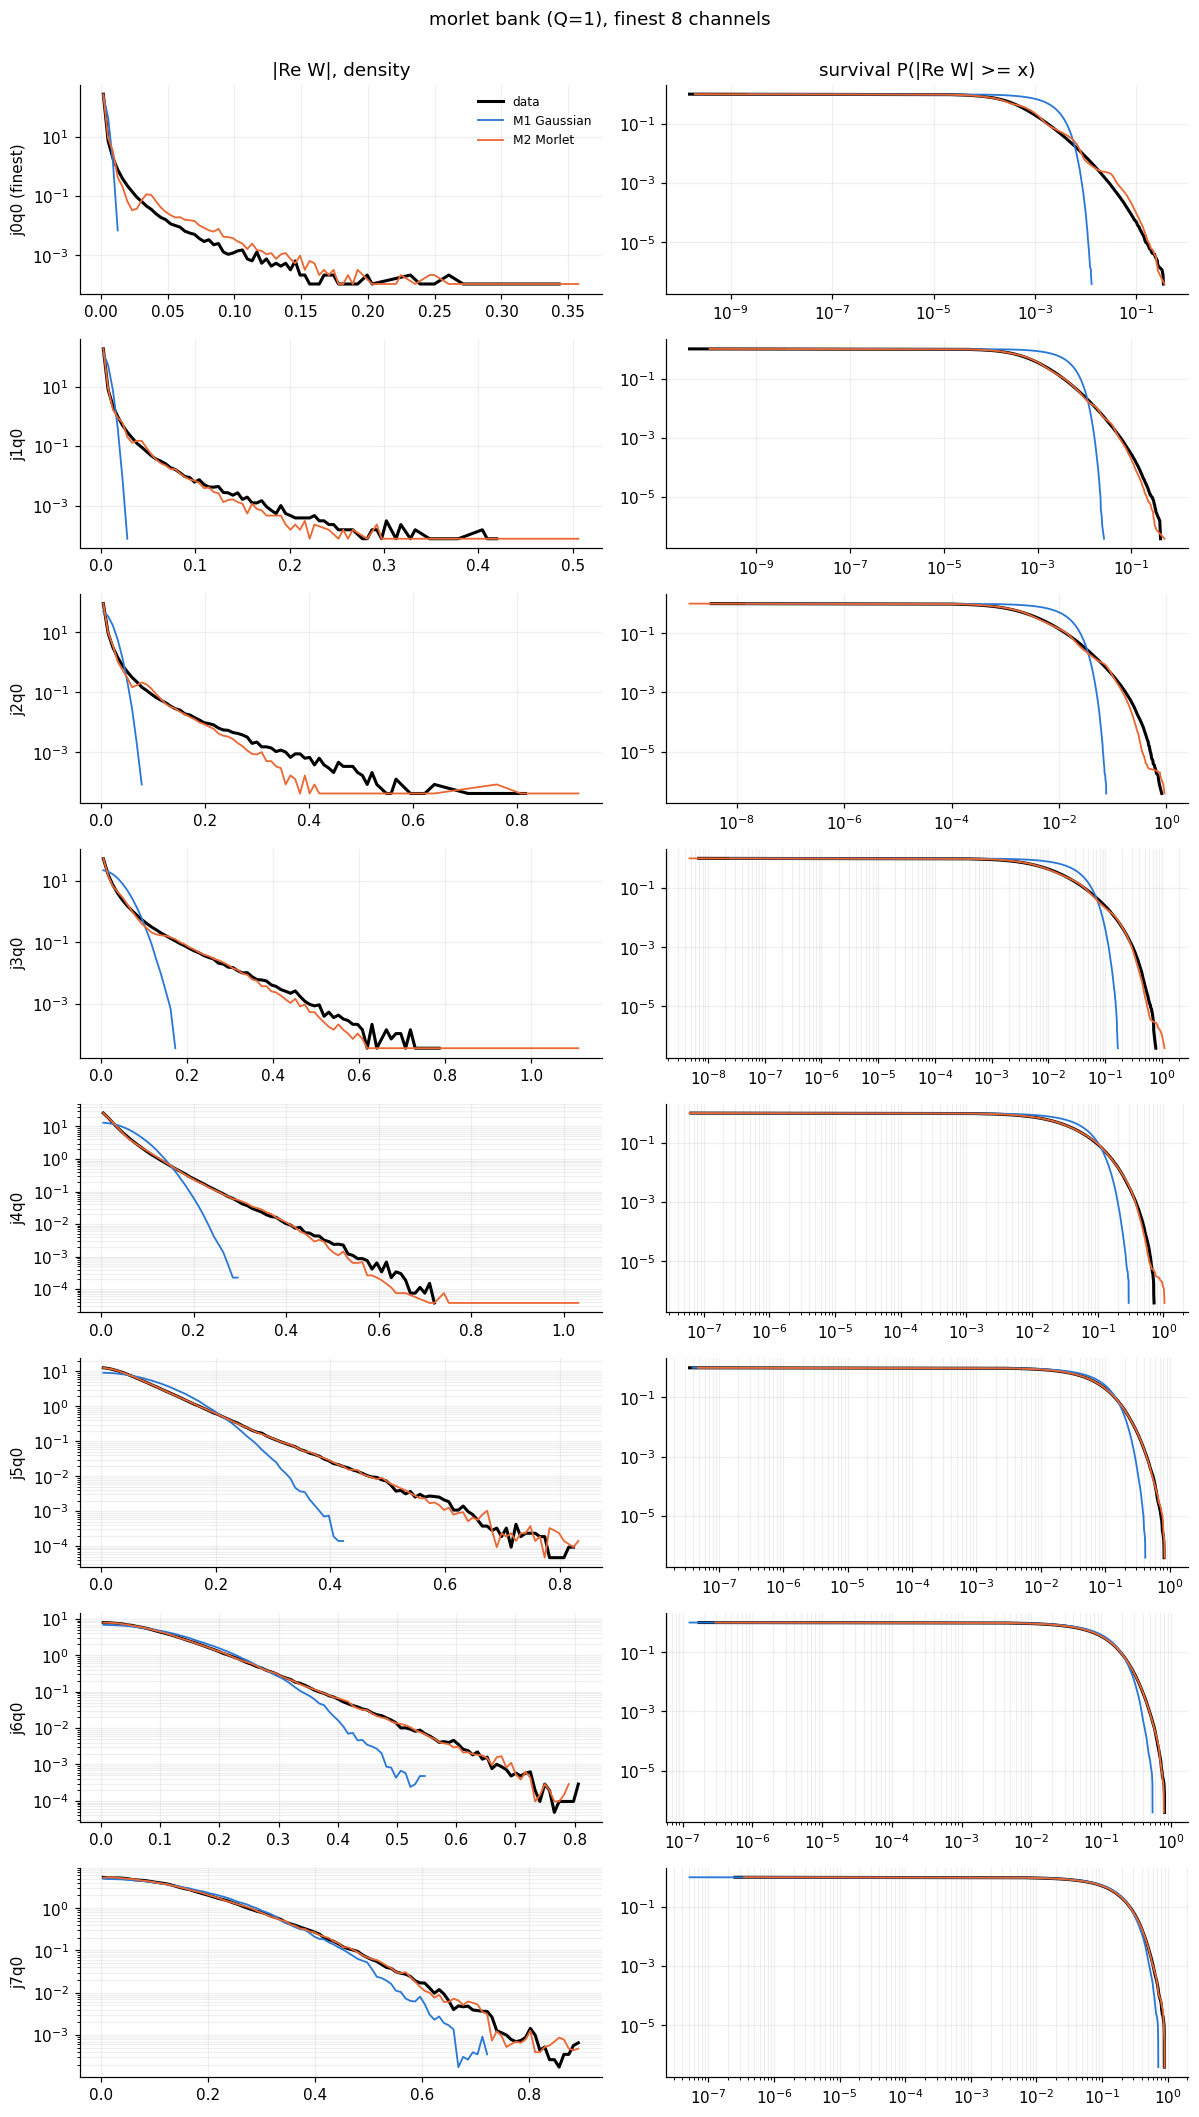

In [6]:
plot_tail_hists(x1, xs, bank='morlet', n_ch=8, n_series=N)

Modulus |x ⋆ ψ| (not imposed by any scalar potential), Q=1 bank:

In [7]:
se.modulus_table(x1, xs, bank='morlet', J=8)

,m2,m4,m6,q0.99,q0.999,q0.9999,m2,m4,m6,q0.99,q0.999,q0.9999
,M1 Gaussian,M1 Gaussian,M1 Gaussian,M1 Gaussian,M1 Gaussian,M1 Gaussian,M2 Morlet,M2 Morlet,M2 Morlet,M2 Morlet,M2 Morlet,M2 Morlet
j0q0,1.185,0.011,0.000,0.780,0.302,0.136,1.692,4.541,11.146,0.981,1.499,1.338
j1q0,1.109,0.033,0.000,0.637,0.294,0.169,1.007,0.772,0.935,1.077,0.937,0.761
j2q0,1.099,0.043,0.001,0.574,0.273,0.192,0.955,0.647,0.366,1.078,0.918,0.806
j3q0,1.068,0.121,0.007,0.554,0.361,0.293,1.009,0.940,0.744,1.044,0.988,0.912
j4q0,1.038,0.311,0.052,0.660,0.510,0.448,1.054,1.106,1.631,1.032,0.979,0.945
j5q0,1.010,0.496,0.148,0.730,0.589,0.570,1.002,0.901,0.712,0.972,0.900,0.868
j6q0,1.016,0.735,0.409,0.842,0.738,0.756,0.997,0.950,0.905,0.958,0.997,0.976
j7q0,0.981,0.847,0.667,0.916,0.881,0.820,0.969,0.946,0.871,0.984,0.909,0.897


Per-sample mean (k = 0 mode) and the ℓ1/ℓ2 ratio per scale (lower = sparser):

,std,excess kurtosis,q0.001,q0.999,std / data
data,0.905,0.080,-2.593,2.899,1.000
M1 Gaussian,0.905,-0.012,-2.659,2.762,1.000
M2 Morlet,0.898,0.076,-2.645,2.610,0.993


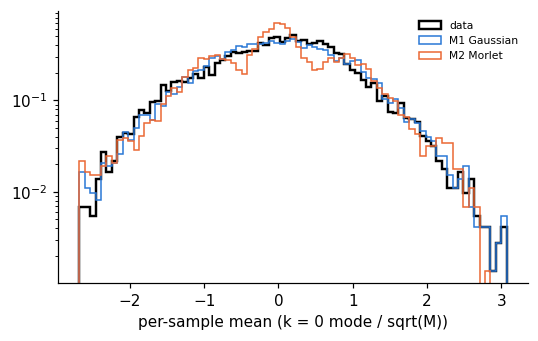

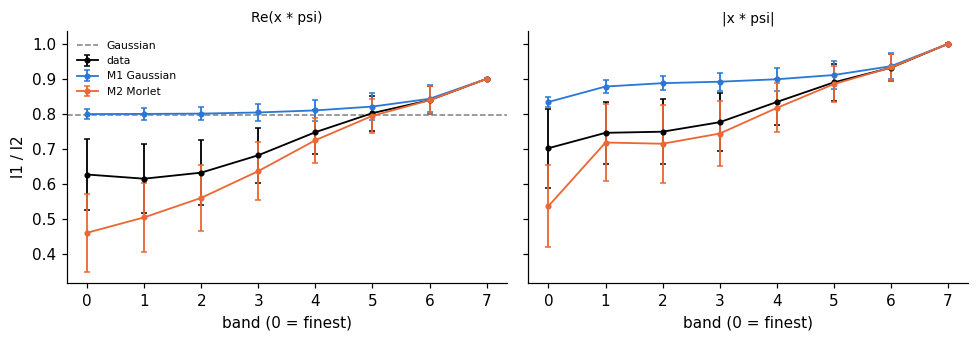

In [8]:
display(se.k0_summary(x1, xs)); se.plot_k0(x1, xs); se.plot_l1l2(x1, xs);

Coefficients of the decimated Db4 DWT per scale (the marginals the Db4 arm imposes; last row = approximation block):

In [9]:
for name, t in dm.dwt_scale_table(x1, xs, order=4, J=8).items():
    print(name); display(t)

M1 Gaussian


,N per series,m2,m4,m6,q0.99,q0.999,q0.9999
j0,128,0.949,0.001,0.000,1.000,0.307,0.109
j1,64,1.030,0.004,0.000,0.808,0.268,0.121
j2,32,0.988,0.032,0.001,0.603,0.288,0.191
j3,16,1.015,0.153,0.012,0.627,0.432,0.346
j4,8,0.982,0.358,0.075,0.734,0.592,0.491
j5,4,1.007,0.578,0.214,0.836,0.708,0.652
j6,2,0.980,0.757,0.492,0.902,0.819,0.836
j7,1,1.027,0.900,0.699,0.956,0.902,0.884
approx,1,1.000,0.970,0.941,0.990,0.976,0.947


M2 Morlet


,N per series,m2,m4,m6,q0.99,q0.999,q0.9999
j0,128,2.052,0.783,0.706,1.710,1.672,1.081
j1,64,0.747,0.142,0.038,1.103,0.780,0.566
j2,32,0.867,0.542,0.376,0.979,0.899,0.768
j3,16,1.003,0.944,0.840,1.008,0.984,0.956
j4,8,0.981,0.912,0.781,0.995,0.962,0.904
j5,4,1.004,0.963,0.901,0.990,0.976,0.958
j6,2,0.976,0.951,0.943,1.007,0.940,1.088
j7,1,1.033,1.077,1.145,1.013,1.000,1.162
approx,1,0.986,0.970,1.000,1.000,0.893,0.822


## 2. log p, concentration and entropy

### 2.1 Summary
`negentropy = H_gauss − H_bound`, with H_gauss the entropy of the Gaussian that has the data covariance. `gap = θ·(m_target − ⟨φ⟩)` = `H_sample − H_bound`. Mean ± std over seeds.

In [10]:
le.summary_table(res, H_gauss=H_gauss)

,seeds,H_bound,H_gauss (data),negentropy H_gauss - H_bound,H_sample (mean -log p),gap = theta.(m_target - <phi>),std(-log p) model,std / H,cross-entropy (data),std(-log p) data
model,,,,,,,,,,
M1 Gaussian,5,-724.80 ± 0.17,-911.83,-187.03 ± 0.17,-724.71 ± 0.17,0.09 ± 0.00,10.93 ± 0.06,0.02 ± 0.00,-724.94 ± 0.18,1169.05 ± 0.34
M2 Morlet,5,-920.09 ± 0.20,-911.83,8.27 ± 0.20,-916.12 ± 0.20,3.97 ± 0.02,37.52 ± 0.25,0.04 ± 0.00,-920.85 ± 0.20,169.20 ± 0.12
M2 Db4 (decimated),0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### 2.2 −log p on model samples (filled) and on data (line)
Centred on the model mean. The cross-entropy (data mean) is in the table above. The M1 panel shows the exact χ²_d prediction.

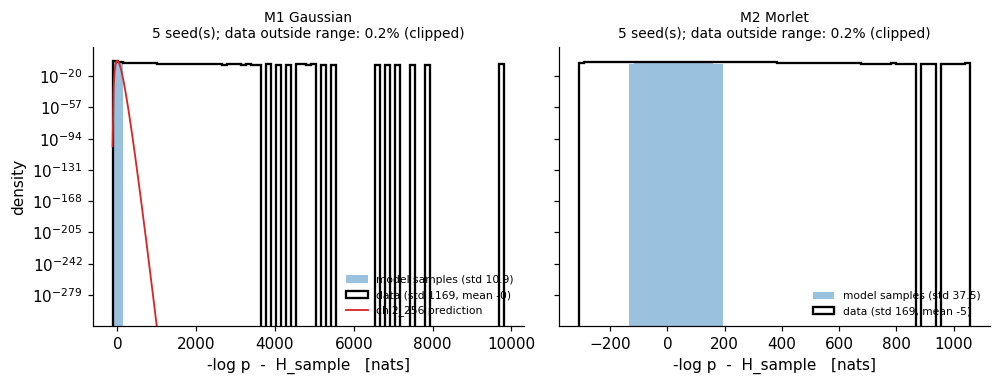

In [11]:
plots.plot_nlogp(res);

### 2.3 Concentration and reproducibility across seeds

,seeds,Pearson mean,Pearson min,Spearman mean,Spearman min
model,,,,,
M1 Gaussian,5,1.000,1.000,1.000,1.000
M2 Morlet,5,1.000,1.000,1.000,1.000


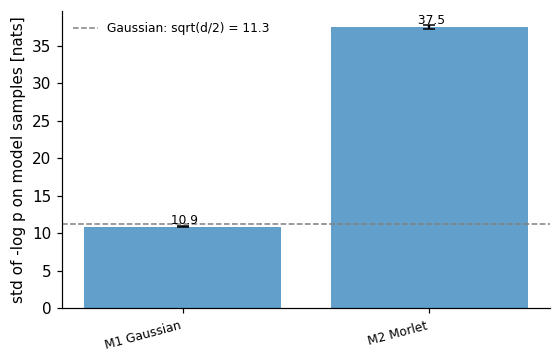

In [12]:
plots.plot_concentration(res); display(plots.seed_agreement(res))

### 2.4 Entropy bound along the transport (dashed: Gaussian with the data covariance)

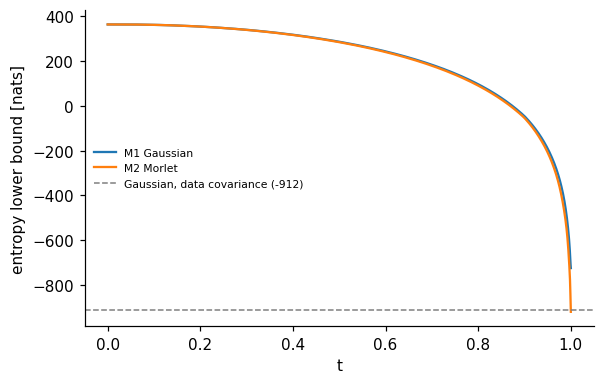

In [13]:
plots.plot_entropy_evolution(runs, H_gauss, d=x1.shape[-1]);

### 2.5 Which potential family and which scale contribute to log p
A split is ill-defined when two families cancel (strong negative correlation with a std far above the total's).

,std(total),ill-defined splits
model,,
M1 Gaussian,10.974,none
M2 Morlet,37.116,none


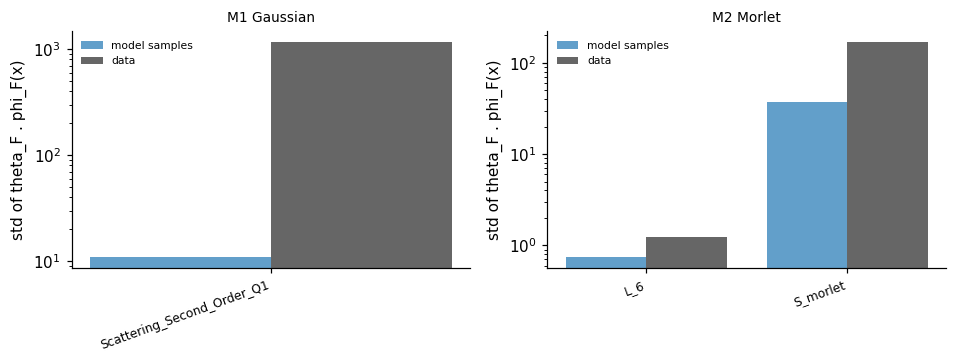

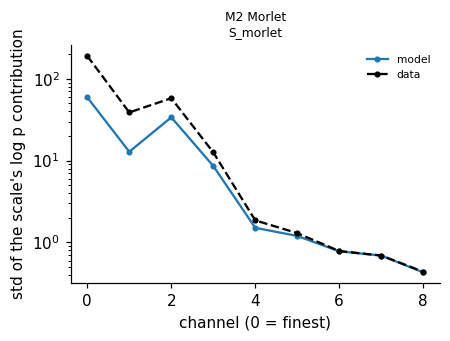

In [14]:
plots.plot_families(res); plots.plot_per_scale(res); display(plots.split_flags(res))

### 2.6 Signs of θ (confinement)
θ < 0 is needed on L_6 and on the outer region (reg3) of each scalar channel. 'Possibly unconfined': both positive on the same channel.

In [15]:
plots.sign_table(res)

,seeds,theta_L6 > 0,theta_outer(reg3) > 0,channels both > 0 (possibly unconfined),Scat2 bands theta > 0
model,,,,,
M1 Gaussian,5,0 / 0,-,-,5
M2 Morlet,5,26 / 45,13 / 45,5,-


### 2.7 M1 check against the exact Gaussian
For Scat2 the fitted model is an exact circulant Gaussian: exact H and log Z, existence (g(ω) < 0 everywhere) and the χ²_d test of −log p on its own samples (`var(y)/2d` → 1).

In [16]:
g = [n for n in res if 'Gaussian' in n and res[n]]
gcheck.validation_table(res[g[0]]) if g else 'no Gaussian model in the registry'

,exists (g<0),H exact,H_bound,H_sample,H_bound - H exact,log Z exact,log Z lower bound,var(y)/2d,KS to chi2_d
seed,,,,,,,,,
900,True,-825.621,-724.705,-724.613,100.916,-953.621,-846.717,0.941,0.009
901,True,-825.713,-724.821,-724.729,100.892,-953.713,-846.852,0.934,0.011
902,True,-825.509,-724.676,-724.584,100.833,-953.509,-846.619,0.942,0.012
903,True,-825.656,-724.694,-724.603,100.962,-953.656,-846.736,0.926,0.013
904,True,-825.665,-725.092,-724.999,100.573,-953.665,-847.153,0.920,0.016


## 3. Samples across −log p
Top row of each model: its samples at quantiles of −log p (0 = most likely, 1 = rarest); below each, the data signal with the closest −log p. Pool: the 10 000 final walkers of seed 900.

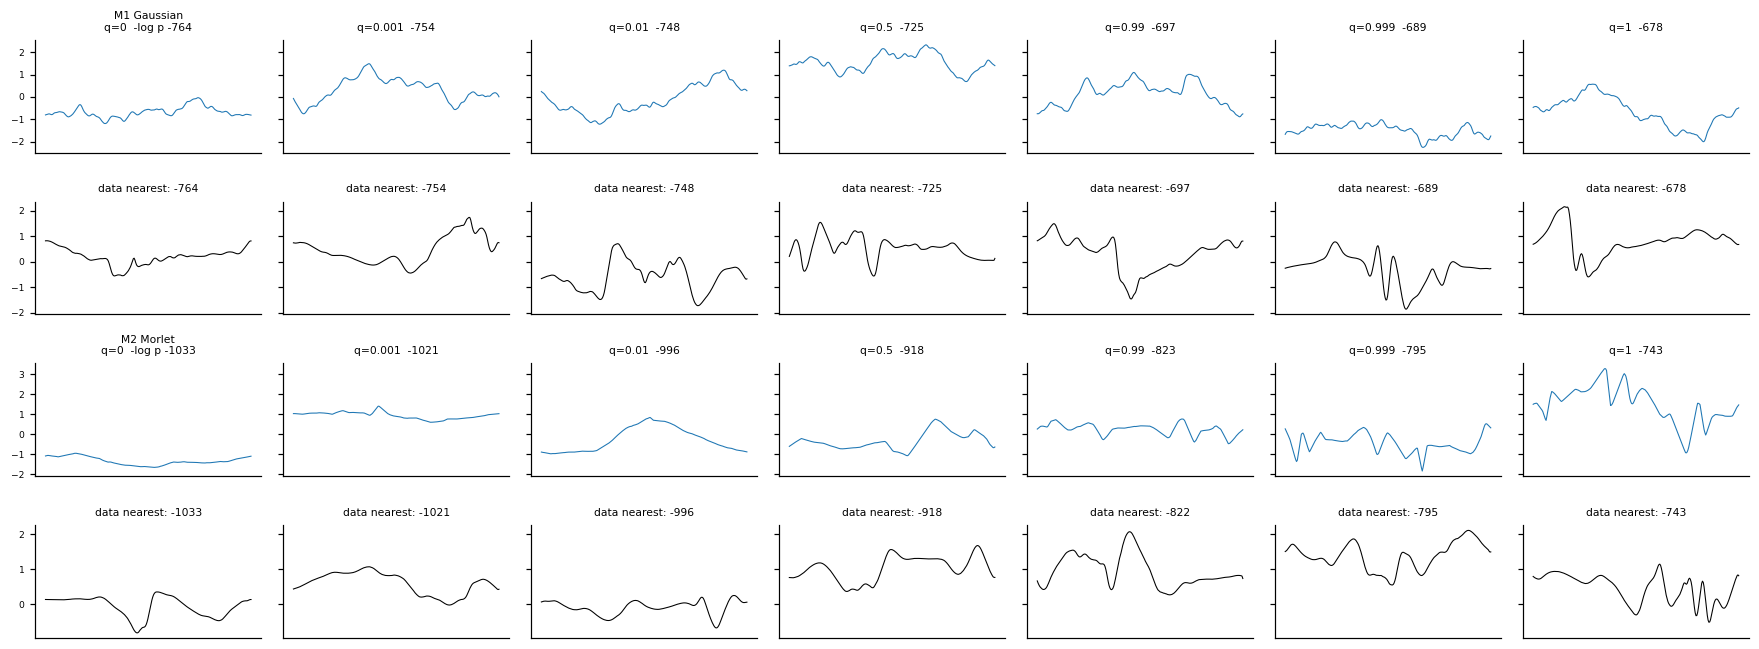

In [17]:
se.plot_gallery(res, xs, x1, seed=SEED);

## Context: physical statistics

,reg,sched,n_terms,nt,n1,runtime_h,mm_final_median,mm_final_p90,mm_final_max,mm_n_above_1pct,S2_ratio_tau1,flat4_ratio_tau1,flat6_ratio_tau1,skew_tau1 (data 0.018),spec_logrms,spec_logrms_oct,wav_E_logrms,wav_flat_logrms,marg_KS,wav_KS_max
M1 Gaussian,0.000,2.000,1.000,55000.000,10000.000,0.400,0.000,0.000,0.000,0.000,1.000,0.067,0.001,0.001,0.433,0.245,0.242,4.585,0.013,0.789
M2 Morlet,0.000,2.000,2.000,55000.000,10000.000,1.300,0.000,0.000,0.147,3.000,0.955,0.960,3.293,0.282,1.463,0.826,0.848,1.487,0.016,0.519


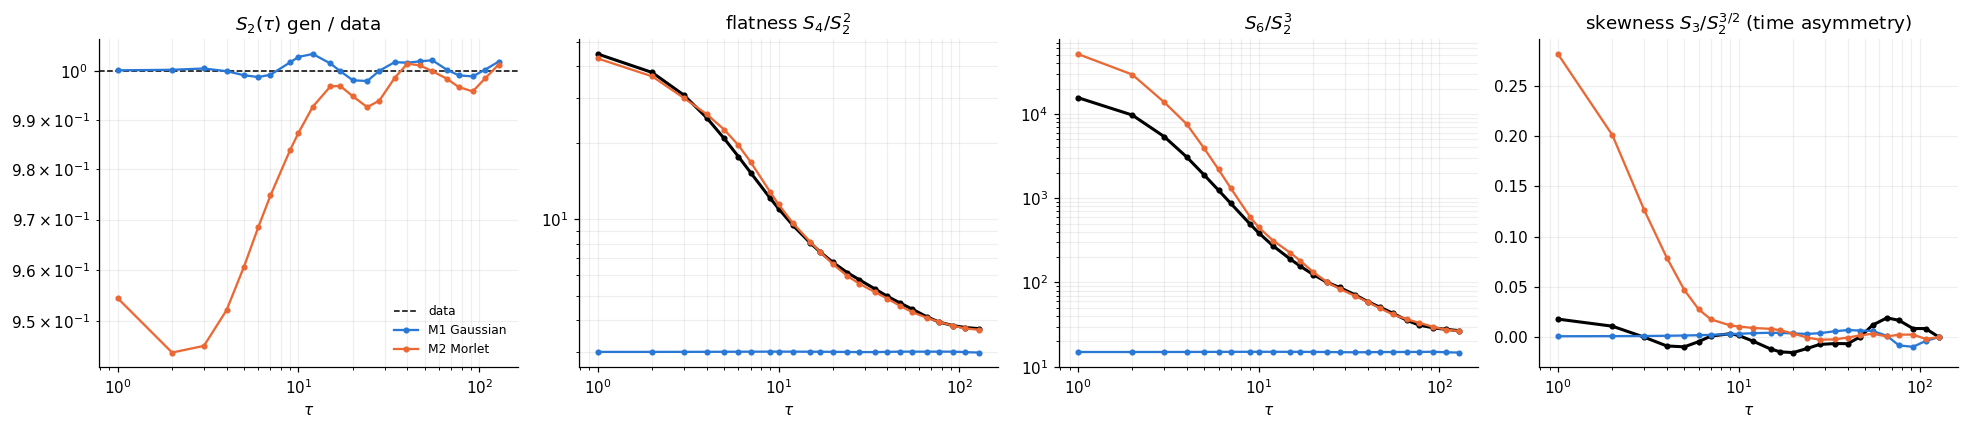

In [18]:
S_ref = compute_stats(x1); S_runs = {k: compute_stats(v) for k, v in xs.items()}
display(summary_table(S_ref, S_runs, runs, THRESHOLD, ks=wavelet_ks(S_ref, S_runs)))
plot_structure(S_ref, S_runs)